In [1]:
import pandas as pd
import numpy as np
import re
import nltk
import math

from collections import defaultdict, Counter
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Part 2: Indexing and Evaluation

## 1. Data Loading and Preprocessing

We reuse the preprocessing pipeline developed in Part 1 (first deliverable)
to ensure that documents and queries follow the same
normalization steps

In [2]:
%pip install nbformat

Note: you may need to restart the kernel to use updated packages.


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Dataset principal: (28080, 17)
Validation labels: (40, 4)
DATA VALIDATION SUMMARY

Dataset shape:
(28080, 17)

Missing values per column:
_id                0
actual_price       0
average_rating     0
brand              0
category           0
crawled_at         0
description        0
discount           0
images             0
out_of_stock       0
pid                0
product_details    0
seller             0
selling_price      0
sub_category       0
title              0
url                0
dtype: int64

Empty strings in important text fields:
title: 0
description: 11150
brand: 2009
category: 0
sub_category: 0
seller: 1643

Duplicate PID values:
0

Unique PID values:
28080

out_of_stock values:
out_of_stock
False    26436
True      1644
Name: count, dtype: int64

Numeric fields summary:


,selling_price,actual_price,average_rating
count,28080,28080,28080
unique,1512,728,39
top,399,999,3.9
freq,1500,3504,2605


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\FA507\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['title', 'pid', 'query_id', 'labels']


,title,pid,query_id,labels
0,Full Sleeve Printed Women Sweatshirt,SWSFFVKBCQG5FHPF,1,1
1,Full Sleeve Striped Women Sweatshirt,SWSFJY5ZFHQ7HXKW,1,0
2,Full Sleeve Printed Women Sweatshirt,SWSFUY89NHMZHZPX,1,1
3,Full Sleeve Graphic Print Women Sweatshirt,SWSFXQ5YX6RZKHP4,1,1
4,Full Sleeve Solid Women Sweatshirt,JCKFTZBC3DMCVYXH,1,0
5,Full Sleeve Graphic Print Women Sweatshirt,SWSFWCTDHRABJFCR,1,1
6,Typography Women V Neck Multicolor T-Shirt (P...,TSHFUH9FABXHSDPJ,1,0
7,Full Sleeve Printed Women Sweatshirt,SWSFVGKENHBSVUWJ,1,1
8,Full Sleeve Solid Women Sweatshirt,JCKF7M8DNBB6WZ8Y,1,1
9,Full Sleeve Graphic Print Women Sweatshirt,SWSFWCSPEGMDH8FV,1,1


,query_id,query,labels,pid,title,title_processed,description_processed,brand_processed,category_processed,sub_category_processed,product_details_processed
0,1,women full sleeve sweatshirt cotton,1,SWSFFVKBCQG5FHPF,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[hoodi, women, stylish, made, 100, premium, co...",[cupidsto],"[cloth, accessori]","[winter, wear]","[color, dark, blue, fabric, cotton, blend, pat..."
1,1,women full sleeve sweatshirt cotton,0,SWSFJY5ZFHQ7HXKW,Full Sleeve Striped Women Sweatshirt,"[full, sleev, stripe, women, sweatshirt]","[squat, press, shuttl, run, women, train, hood...",[reeb],"[cloth, accessori]","[winter, wear]","[color, black, fabric, polyest, blend, pattern..."
2,1,women full sleeve sweatshirt cotton,1,SWSFUY89NHMZHZPX,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, live, larg, big, logo, women,...",[pu],"[cloth, accessori]","[winter, wear]","[color, red, fabric, cotton, blend, pattern, p..."
3,1,women full sleeve sweatshirt cotton,1,SWSFXQ5YX6RZKHP4,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, print, sweatshirt, fea...","[free, authori]","[cloth, accessori]","[winter, wear]","[color, yellow, fabric, polycotton, pattern, g..."
4,1,women full sleeve sweatshirt cotton,0,JCKFTZBC3DMCVYXH,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[product, stori, embrac, next, gener, sport, u...",[pu],"[cloth, accessori]","[winter, wear]","[color, green, fabric, cotton, blend, pattern,..."
5,1,women full sleeve sweatshirt cotton,1,SWSFWCTDHRABJFCR,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, terri, swe...","[free, authori]","[cloth, accessori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
6,1,women full sleeve sweatshirt cotton,0,TSHFUH9FABXHSDPJ,Typography Women V Neck Multicolor T-Shirt (P...,"[typographi, women, v, neck, multicolor, shirt...","[free, author, present, v, neck, tee, combo, f...","[free, authori]","[cloth, accessori]",[topwear],"[type, v, neck, sleev, half, sleev, fit, regul..."
7,1,women full sleeve sweatshirt cotton,1,SWSFVGKENHBSVUWJ,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, celebr, global, connect, fash...",[pu],"[cloth, accessori]","[winter, wear]","[color, white, fabric, cotton, blend, pattern,..."
8,1,women full sleeve sweatshirt cotton,1,JCKF7M8DNBB6WZ8Y,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[reebok, bomber, track, jacket, women, comfort...",[reeb],"[cloth, accessori]","[winter, wear]","[color, black, fabric, cotton, blend, pattern,..."
9,1,women full sleeve sweatshirt cotton,1,SWSFWCSPEGMDH8FV,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, sweatshirt...","[free, authori]","[cloth, accessori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."


,query_id,query,title,title_processed,description_processed,brand_processed,sub_category_processed,product_details_processed
0,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[hoodi, women, stylish, made, 100, premium, co...",[cupidsto],"[winter, wear]","[color, dark, blue, fabric, cotton, blend, pat..."
2,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, live, larg, big, logo, women,...",[pu],"[winter, wear]","[color, red, fabric, cotton, blend, pattern, p..."
3,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, print, sweatshirt, fea...","[free, authori]","[winter, wear]","[color, yellow, fabric, polycotton, pattern, g..."
5,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, terri, swe...","[free, authori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
7,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, celebr, global, connect, fash...",[pu],"[winter, wear]","[color, white, fabric, cotton, blend, pattern,..."
8,1,women full sleeve sweatshirt cotton,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[reebok, bomber, track, jacket, women, comfort...",[reeb],"[winter, wear]","[color, black, fabric, cotton, blend, pattern,..."
9,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, sweatshirt...","[free, authori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
10,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[wear, nasa, logo, edit, women, cotton, sweats...","[tee, bud]","[winter, wear]","[color, grey, fabric, pure, cotton, pattern, g..."
14,1,women full sleeve sweatshirt cotton,Full Sleeve Color Block Women Sweatshirt,"[full, sleev, color, block, women, sweatshirt]","[freshen, winter, wardrob, sweatshirt, women, ...","[jack, har]","[winter, wear]","[color, multicolor, fabric, fleec, pattern, co..."
15,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[temperatur, dip, lower, time, invest, sweatsh...","[free, authori]","[winter, wear]","[color, maroon, fabric, pure, cotton, pattern,..."


title_processed_coverage  description_processed_coverage  \
query_id labels                                                             
1        0                          0.457                           0.629   
         1                          0.800                           0.585   
2        0                          0.725                           0.400   
         1                          0.800                           0.350   

                 brand_processed_coverage  category_processed_coverage  \
query_id labels                                                          
1        0                            0.0                          0.0   
         1                            0.0                          0.0   
2        0                            0.0                          0.0   
         1                            0.0                          0.0   

                 sub_category_processed_coverage  \
query_id labels                                    
1        0                                   0.0   
         1                                   0.0   
2        0                                   0.0   
         1                                   0.0   

                 product_details_processed_coverage  
query_id labels                                      
1        0                                    0.600  
         1                                    0.800  
2        0                                    0.475  
         1                                    0.650

VOCABULARY STATISTICS
Total tokens in titles: 176,056
Unique vocabulary size in titles: 728
Total tokens in descriptions: 528,498
Unique vocabulary size in descriptions: 4,697
Total unique vocabulary size across all search fields: 19,613

DOCUMENT LENGTH METRICS


,title_word_count,desc_word_count,desc_avg_sentence_length
count,28080.00,28080.00,28080.00
mean,6.27,18.82,11.25
std,1.98,26.69,14.78
min,1.00,0.00,0.00
25%,5.00,0.00,0.00
50%,6.00,9.00,9.33
75%,7.00,29.00,18.00
max,31.00,579.00,191.00


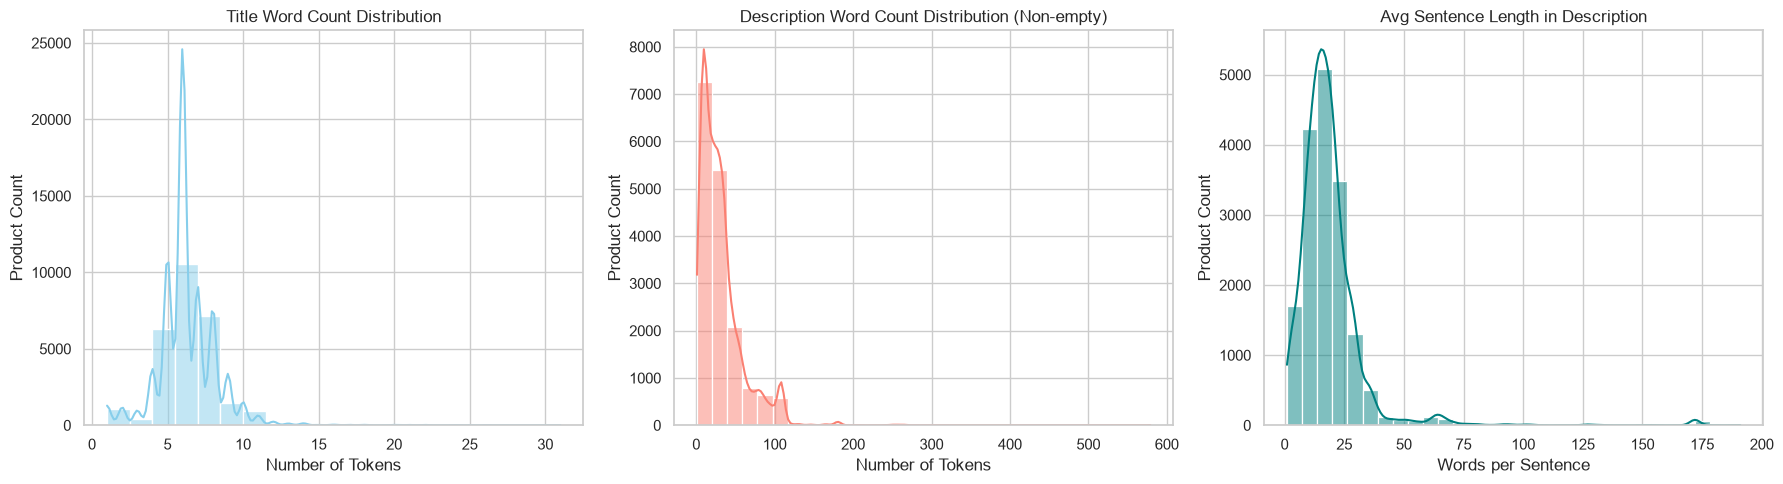

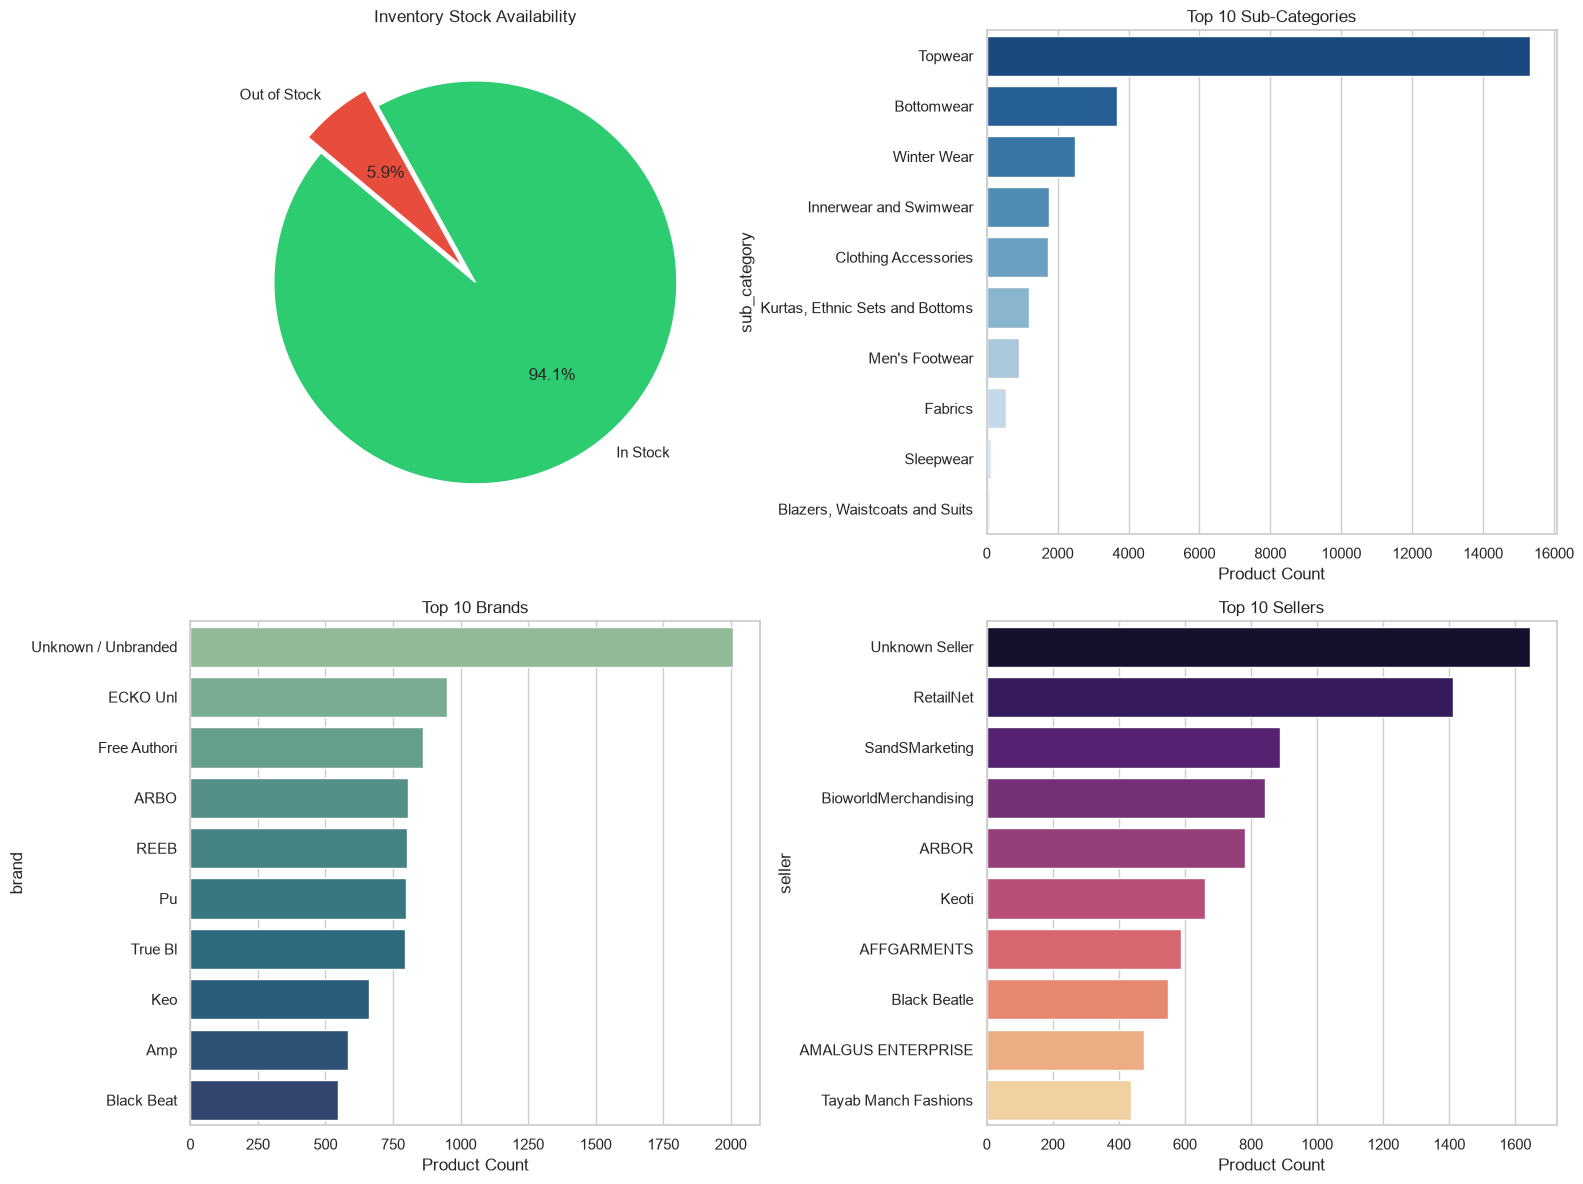

NUMERICAL ATTRIBUTES SUMMARY


,selling_price_numeric,actual_price_numeric,discount_numeric,average_rating_numeric
count,28078.00,27303.00,27225.00,25819.00
mean,705.64,1455.53,50.26,3.63
std,549.68,939.98,16.89,0.66
min,99.00,150.00,1.00,1.00
25%,390.00,849.00,40.00,3.20
50%,545.00,1199.00,53.00,3.80
75%,820.00,1799.00,63.00,4.10
max,7999.00,12999.00,87.00,5.00



TOP 5 HIGHEST RATED PRODUCTS


,pid,title,brand,average_rating_numeric,selling_price_numeric
13251,VESFSJ92YXMAJZFX,Sheny Women Vest,,5.0,184.0
9482,TSHFJHFFQHQBNVSV,Solid Women Round Neck Red T-Shirt,FancyW,5.0,215.0
4683,TSHFVUXHTE5KH7RH,Solid Men Polo Neck Dark Blue T-Shirt,Shoef,5.0,246.0
417,BXRFGYUGJCWWZ7UG,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0



TOP 5 HIGHEST DISCOUNTED PRODUCTS (%)


,pid,title,brand,actual_price_numeric,selling_price_numeric,discount_numeric
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,998.0,128.0,87.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,999.0,136.0,86.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,999.0,136.0,86.0
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvib,2999.0,449.0,85.0
9813,CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,1499.0,228.0,84.0



TOP 5 MOST EXPENSIVE PRODUCTS


,pid,title,brand,selling_price_numeric,actual_price_numeric
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,9999.0
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,True Bl,7998.0,7999.0
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,12999.0
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,12999.0
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,12990.0


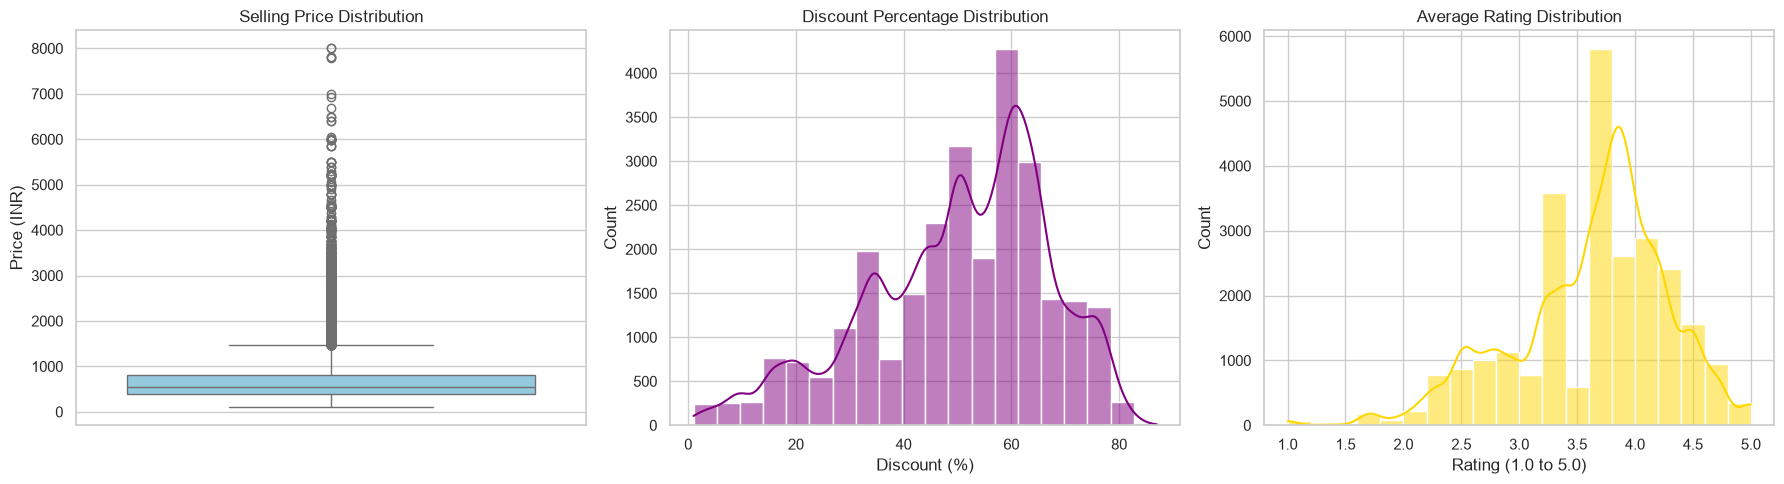

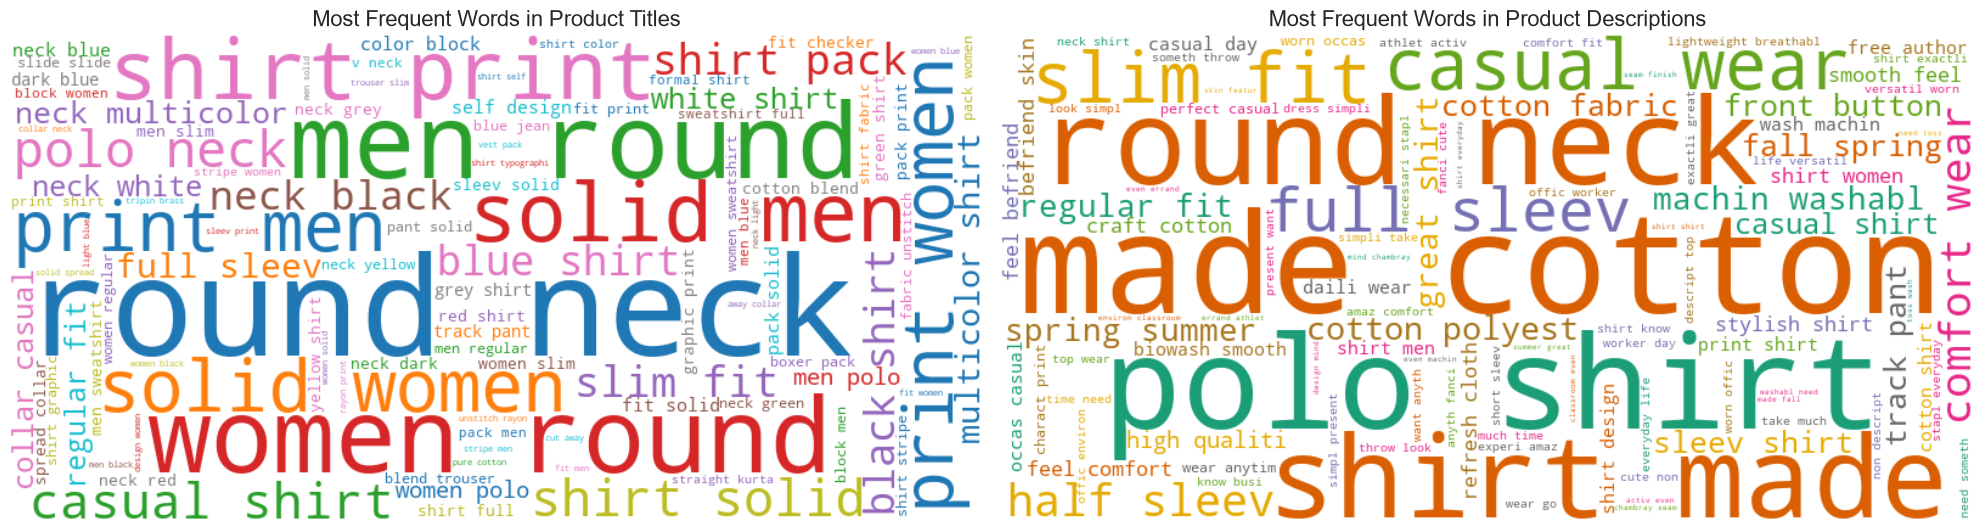

NAMED ENTITY RECOGNITION SUMMARY
Entity Label Counts:
Label
ORG            1382
PERSON          634
CARDINAL        558
GPE              38
WORK_OF_ART      22
FAC               4
PERCENT           3
DATE              3
QUANTITY          1
Name: count, dtype: int64

Top Entities per Category:
Label        Entity                                       
CARDINAL     2                                                220
             3                                                196
             4                                                 31
             6                                                 29
             1                                                 27
DATE         2021                                               1
             1307-9                                             1
             2010                                               1
FAC          Crew Black                                         2
             Tamil Nadu Parambariya                  

C:\Users\FA507\AppData\Local\Temp\ipykernel_19432\1709998728.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_entities, x="Label", order=df_entities["Label"].value_counts().index, palette="Set2")


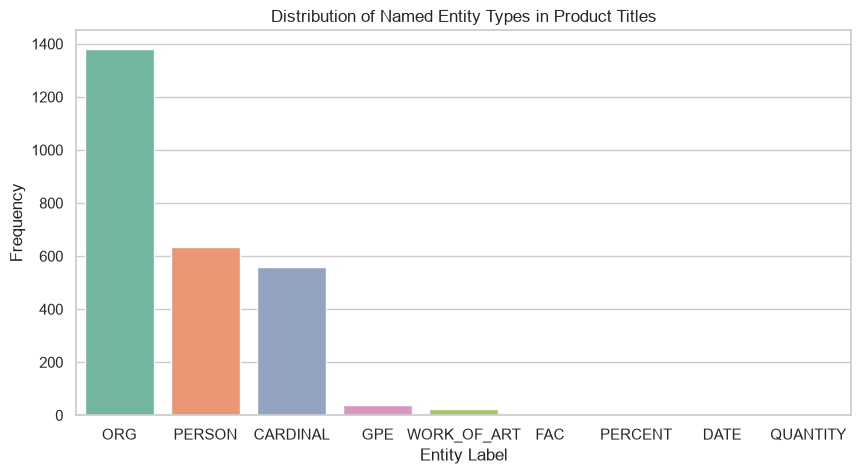

In [3]:
%run "../Part1/Text_Processing_and_Exploratory_Data_Analysis_IRWA.ipynb"

In [4]:
print("Total documents:", len(df_processed))
print("Unique PIDs:", df_processed["pid"].nunique())

display(
    df_processed[["pid", "title", "search_tokens"]].head()
)

Total documents: 28080
Unique PIDs: 28080


,pid,title,search_tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant, yorker, trackp..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant, yorker, ..."
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker..."
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant, yorke..."


## 2. Inverted Index Construction

We build an inverted index using the processed tokens from Part 1.
Each term is associated with the product IDs (pid) of the documents
that contain it

In [5]:
from collections import defaultdict

def build_inverted_index(df):
    inverted_index = defaultdict(set)

    for _, row in df.iterrows():
        pid = row["pid"]
        tokens = row["search_tokens"]

        for term in tokens:
            inverted_index[term].add(pid)

    return dict(inverted_index)


inverted_index = build_inverted_index(df_processed)

print("Number of indexed terms:", len(inverted_index))

Number of indexed terms: 19613


## 3. Conjunctive Query Processing (AND)

We implement conjunctive retrieval, where a document is returned
only if it contains all query terms.

Queries are processed using the same normalization pipeline
developed in Part 1

In [6]:
def search_AND(query, inverted_index):
    # Apply the same preprocessing used for documents
    query_terms = preprocess_text(query)

    if not query_terms:
        return set()

    # Retrieve the documents containing each query term
    posting_lists = [
        inverted_index.get(term, set())
        for term in query_terms
    ]

    # AND operation: intersection of all posting lists
    matching_docs = set.intersection(*posting_lists)

    return matching_docs

In [7]:
queries = [
    "blue jeans",
    "cotton shirt",
    "women sweatshirt",
    "men slim jeans blue"
]

for query in queries:
    results = search_AND(query, inverted_index)
    print(f"{query}: {len(results)} matching documents")

blue jeans: 1082 matching documents
cotton shirt: 13161 matching documents
women sweatshirt: 685 matching documents
men slim jeans blue: 222 matching documents


In [8]:
query = "blue jeans"

results = search_AND(query, inverted_index)
query_terms = preprocess_text(query)

assert all(
    set(query_terms).issubset(
        set(df_processed.loc[df_processed["pid"] == pid, "search_tokens"].iloc[0])
    )
    for pid in results
)

print("AND retrieval test passed!")

AND retrieval test passed!


## 4. Test Query Selection

We selected five queries with different product attributes and
levels of specificity to test how the search engine behaves
with conjunctive retrieval

In [9]:
test_queries = [
    "men winter hooded sweatshirt",
    "women black full sleeve round neck top",
    "men blue slim fit jeans",
    "women cotton printed kurta",
    "men black polo shirt"
]

query_results = {}

for query in test_queries:
    results = search_AND(query, inverted_index)
    query_results[query] = results

    print(f"{query:<42} {len(results):>6} documents")

men winter hooded sweatshirt                  717 documents
women black full sleeve round neck top          4 documents
men blue slim fit jeans                       126 documents
women cotton printed kurta                     44 documents
men black polo shirt                          231 documents


## 5. TF-IDF Ranking

After retrieving documents using conjunctive (AND) queries, we rank
the matching products using TF-IDF

TF-IDF assigns weights to terms based on their frequency within a
document and how common they are across the collection. Then we use cosine similarity between the query vector and document
vectors to rank the retrieved products

In [10]:
import math

def compute_idf(inverted_index, total_docs):
    idf = {}

    for term, posting_list in inverted_index.items():
        document_frequency = len(posting_list)

        idf[term] = math.log(total_docs / document_frequency)

    return idf


idf = compute_idf(inverted_index, len(df_processed))

print("IDF for 'cotton':", round(idf["cotton"], 3))
print("IDF for 'jean':", round(idf["jean"], 3))

IDF for 'cotton': 0.343
IDF for 'jean': 2.444


In [11]:
from collections import Counter

def compute_document_vectors(df, idf):
    doc_vectors = {}

    for _, row in df.iterrows():
        pid = row["pid"]
        tokens = row["search_tokens"]

        term_counts = Counter(tokens)

        vector = {}

        for term, frequency in term_counts.items():
            tf = frequency
            vector[term] = tf * idf[term]

        # L2 normalization
        norm = math.sqrt(sum(weight**2 for weight in vector.values()))

        if norm > 0:
            vector = {
                term: weight / norm
                for term, weight in vector.items()
            }

        doc_vectors[pid] = vector

    return doc_vectors


doc_vectors = compute_document_vectors(df_processed, idf)

print("Document vectors created:", len(doc_vectors))

Document vectors created: 28080


In [12]:
print("Example PID:", df_processed.iloc[0]["pid"])

first_pid = df_processed.iloc[0]["pid"]

print("Number of terms:", len(doc_vectors[first_pid]))

print("First 10 TF-IDF weights:")
print(list(doc_vectors[first_pid].items())[:10])

Example PID: TKPFCZ9EA7H5FYZH
Number of terms: 42
First 10 TF-IDF weights:
[('solid', 0.07240729529836808), ('women', 0.030297331626969504), ('multicolor', 0.15036752695573408), ('track', 0.11699349719228301), ('pant', 0.11121518406203428), ('yorker', 0.30364577719370567), ('trackpant', 0.18613155034728773), ('made', 0.15444189503224254), ('100', 0.09219370598818293), ('rich', 0.3628343067238484)]


### Query Vectorization and Cosine Similarity

We apply the same preprocessing and TF-IDF weighting to the queries.
Then, we calculate cosine similarity between each query and the documents
retrieved by the AND search

Since both vectors are L2-normalized, cosine similarity can be computed
using their dot product

In [13]:
def compute_query_vector(query, idf):
    query_terms = preprocess_text(query)
    term_counts = Counter(query_terms)

    query_vector = {}

    for term, frequency in term_counts.items():
        if term in idf:
            tf = frequency
            query_vector[term] = tf * idf[term]

    # L2 normalization
    norm = math.sqrt(sum(weight**2 for weight in query_vector.values()))

    if norm > 0:
        query_vector = {
            term: weight / norm
            for term, weight in query_vector.items()
        }

    return query_vector

In [14]:
def cosine_similarity(query_vector, doc_vector):
    score = 0

    for term, query_weight in query_vector.items():
        doc_weight = doc_vector.get(term, 0)
        score += query_weight * doc_weight

    return score

In [15]:
def rank_documents(query, inverted_index, doc_vectors, idf):
    # First retrieve matching documents using AND
    matching_docs = search_AND(query, inverted_index)

    # Build the query TF-IDF vector
    query_vector = compute_query_vector(query, idf)

    # Calculate similarity for each matching document
    ranked_results = []

    for pid in matching_docs:
        score = cosine_similarity(query_vector, doc_vectors[pid])
        ranked_results.append((pid, score))

    # Sort by score (descending)
    ranked_results.sort(key=lambda x: (-x[1], x[0]))

    return ranked_results

In [16]:
query = "men blue slim fit jeans"

ranked_results = rank_documents(
    query,
    inverted_index,
    doc_vectors,
    idf
)

print("Total matching documents:", len(ranked_results))

print("\nTop 10 ranked products:")

for pid, score in ranked_results[:10]:
    print(f"PID: {pid} | TF-IDF score: {score:.4f}")

Total matching documents: 126

Top 10 ranked products:
PID: JEAFJM2P2FQQJF3C | TF-IDF score: 0.4766
PID: JEAEVJGUSXRNSHRY | TF-IDF score: 0.4538
PID: JEAFUZXT6BYHVNF2 | TF-IDF score: 0.4320
PID: JEAFUZXPUWKSKGVD | TF-IDF score: 0.4318
PID: JEAFUZXRDZWSYWGG | TF-IDF score: 0.4318
PID: JEAFSKYH539HTZB8 | TF-IDF score: 0.4290
PID: JEAEJYZ8KAGSABDQ | TF-IDF score: 0.4285
PID: JEAFUZXUGWXHUF5F | TF-IDF score: 0.4207
PID: JEAFXUHA5YF8WYQY | TF-IDF score: 0.4190
PID: JEAF8HYN5B9ZU6FP | TF-IDF score: 0.4117


In [17]:
products_by_pid = df_processed.set_index("pid")

for position, (pid, score) in enumerate(ranked_results[:10], start=1):
    title = products_by_pid.loc[pid, "title"]

    print(f"{position}. {title}")
    print(f"   PID: {pid} | Score: {score:.4f}")

1. Slim Men Dark Blue Jeans
   PID: JEAFJM2P2FQQJF3C | Score: 0.4766
2. Slim Men Dark Blue Jeans
   PID: JEAEVJGUSXRNSHRY | Score: 0.4538
3. Tapered Fit Men Blue Jeans
   PID: JEAFUZXT6BYHVNF2 | Score: 0.4320
4. Tapered Fit Men Blue Jeans
   PID: JEAFUZXPUWKSKGVD | Score: 0.4318
5. Tapered Fit Men Blue Jeans
   PID: JEAFUZXRDZWSYWGG | Score: 0.4318
6. Tapered Fit Men Blue Jeans
   PID: JEAFSKYH539HTZB8 | Score: 0.4290
7. Slim Men Dark Blue Jeans
   PID: JEAEJYZ8KAGSABDQ | Score: 0.4285
8. Jogger Fit Men Blue Jeans
   PID: JEAFUZXUGWXHUF5F | Score: 0.4207
9. Tapered Fit Men Blue Jeans
   PID: JEAFXUHA5YF8WYQY | Score: 0.4190
10. Slim Men Blue Jeans
   PID: JEAF8HYN5B9ZU6FP | Score: 0.4117


### Observations on TF-IDF Ranking

For the query **"men blue slim fit jeans"**, the system retrieved 126 documents. The top-ranked products are generally related to the query, with items such as "Slim Men Dark Blue Jeans" appearing in the first positions.

However, we also noticed that some results are labeled as "Tapered Fit" or "Jogger Fit" instead of "Slim Fit". This may happen because our `search_tokens` field combines the title, description and other product attributes. As a result, a product can match the word "slim" in its description even if its title indicates a different fit.

This shows one limitation of our current approach: matching all query terms does not always mean that a product fully satisfies the user's search intent. A possible improvement for future parts would be to assign higher weights to title matches

## 6. Ranking Results for Test Queries

We apply TF-IDF ranking to the five selected queries and inspect
the top 10 retrieved products.

The goal is to check whether the highest-ranked results match
the requested product attributes.

In [18]:
all_ranked_results = {}

for query in test_queries:

    ranked = rank_documents(
        query,
        inverted_index,
        doc_vectors,
        idf
    )

    all_ranked_results[query] = ranked

    print(f"\nQUERY: {query}")
    print(f"Total matching documents: {len(ranked)}")

    top_results = []

    for position, (pid, score) in enumerate(ranked[:10], start=1):

        product = products_by_pid.loc[pid]

        top_results.append({
            "Rank": position,
            "PID": pid,
            "Title": product["title"],
            "Score": round(score, 4)
        })

    display(pd.DataFrame(top_results))


QUERY: men winter hooded sweatshirt
Total matching documents: 717


,Rank,PID,Title,Score
0,1,SWSFYQHWQBYUQHNJ,Full Sleeve Printed Men Sweatshirt,0.7460
1,2,SWSFYQGK9ZJSMSXN,Full Sleeve Solid Men Sweatshirt,0.7414
2,3,SWSFYTVTJHEYHQMM,Full Sleeve Printed Men Sweatshirt,0.7002
3,4,SWSFYQGMPY29CDEG,Full Sleeve Printed Men Sweatshirt,0.6596
4,5,SWSFYQFQZTYY3YVM,Full Sleeve Printed Men Sweatshirt,0.6555
5,6,SWSFYRH5Z8FMMGHZ,Full Sleeve Solid Men Sweatshirt,0.6447
6,7,SWSFXMFPRTY4GKGF,Full Sleeve Printed Men Sweatshirt,0.6196
7,8,SWSFXMFPYYTZUZ3Z,Full Sleeve Printed Men Sweatshirt,0.6154
8,9,SWSFZ2H5XK7TJZRS,Full Sleeve Solid Men Sweatshirt,0.5961
9,10,SWSFXV6GGZWJEDKJ,Full Sleeve Solid Men Sweatshirt,0.5957



QUERY: women black full sleeve round neck top
Total matching documents: 4


,Rank,PID,Title,Score
0,1,TSHFZ9TRSRGB8FJA,Graphic Print Women Round Neck Black T-Shirt,0.1929
1,2,TSHFZ9QGYY8GA7SW,Graphic Print Women Round Neck Black T-Shirt,0.1860
2,3,SWTFVMSDDZRPXAPT,Striped Round Neck Casual Women Reversible Red...,0.1605
3,4,TSHFUY8HGS6GCGWA,Printed Women Round Neck Black T-Shirt,0.1440



QUERY: men blue slim fit jeans
Total matching documents: 126


,Rank,PID,Title,Score
0,1,JEAFJM2P2FQQJF3C,Slim Men Dark Blue Jeans,0.4766
1,2,JEAEVJGUSXRNSHRY,Slim Men Dark Blue Jeans,0.4538
2,3,JEAFUZXT6BYHVNF2,Tapered Fit Men Blue Jeans,0.4320
3,4,JEAFUZXPUWKSKGVD,Tapered Fit Men Blue Jeans,0.4318
4,5,JEAFUZXRDZWSYWGG,Tapered Fit Men Blue Jeans,0.4318
5,6,JEAFSKYH539HTZB8,Tapered Fit Men Blue Jeans,0.4290
6,7,JEAEJYZ8KAGSABDQ,Slim Men Dark Blue Jeans,0.4285
7,8,JEAFUZXUGWXHUF5F,Jogger Fit Men Blue Jeans,0.4207
8,9,JEAFXUHA5YF8WYQY,Tapered Fit Men Blue Jeans,0.4190
9,10,JEAF8HYN5B9ZU6FP,Slim Men Blue Jeans,0.4117



QUERY: women cotton printed kurta
Total matching documents: 44


,Rank,PID,Title,Score
0,1,KTAF5SD3WHM2V9HZ,Women Printed Cotton Blend Straight Kurta (Or...,0.6108
1,2,KTAFZCK5RGNECHHH,Women Printed Cotton Linen Blend Straight Kurt...,0.5744
2,3,KTAFD3ZMEMREHQHS,Women Printed Cotton Blend Straight Kurta (Or...,0.5636
3,4,KTAFD3ZMPXPC3GE4,Women Printed Cotton Blend Straight Kurta (Or...,0.5636
4,5,KTAFD3ZMWMWFHWHH,Women Printed Cotton Blend Straight Kurta (Or...,0.5636
5,6,KTAFD3ZMZSMMHB5C,Women Printed Cotton Blend Straight Kurta (Or...,0.5636
6,7,KTAFZCH5BCNAFZJ6,Women Printed Cotton Linen Blend Straight Kurt...,0.5604
7,8,KTAFZCH5954HZSWJ,Women Printed Cotton Linen Blend Straight Kurt...,0.5539
8,9,KTAFDVG4YZBS44WT,Women Printed Cotton Blend Straight Kurta (Bl...,0.5463
9,10,KTAFZ9KFEAFVMWFN,Women Polka Print Cotton Blend A-line Kurta (...,0.5422



QUERY: men black polo shirt
Total matching documents: 231


,Rank,PID,Title,Score
0,1,TSHFWYV9GJ8FWQGG,Solid Men Polo Neck Black T-Shirt,0.6836
1,2,TSHE7UBH7ZAMA8NG,Solid Men Polo Neck Black T-Shirt,0.6409
2,3,TSHFGQGQZPVZHD2S,Solid Men Polo Neck Black T-Shirt,0.6387
3,4,TSHFZQBG3J5GREG2,Printed Men Polo Neck Black T-Shirt,0.6324
4,5,TSHFUGNWKWGPZ32S,Solid Men Polo Neck Black T-Shirt,0.5999
5,6,TSHFV8YFJGXRZESG,Printed Men Polo Neck Black T-Shirt,0.5865
6,7,TSHFZQ9RWFAN3U6J,Printed Men Polo Neck Black T-Shirt,0.5844
7,8,TSHF3UHYNWES4KUH,"Solid Men Polo Neck Black, Grey T-Shirt",0.5709
8,9,TSHF3UHYRJU8XJE5,"Solid Men Polo Neck Black, Grey T-Shirt",0.5709
9,10,TSHFGGUDH35HPFAG,Woven Men Polo Neck Black T-Shirt,0.5684


In [19]:
for query in test_queries:
    ranked = all_ranked_results[query]
    query_terms = set(preprocess_text(query))

    assert all(
        query_terms.issubset(
            set(products_by_pid.loc[pid, "search_tokens"])
        )
        for pid, score in ranked
    )

    scores = [score for pid, score in ranked]

    assert scores == sorted(scores, reverse=True)

    print(f"PASSED: {query}")

PASSED: men winter hooded sweatshirt
PASSED: women black full sleeve round neck top
PASSED: men blue slim fit jeans
PASSED: women cotton printed kurta
PASSED: men black polo shirt


### Ranking Results Validation

We tested the TF-IDF ranking for all five queries and verified that the results satisfy the AND retrieval condition. All tests passed, confirming that every retrieved document contains all the processed query terms. We also checked that the TF-IDF scores are sorted in descending order. Therefore, the retrieval and ranking functions behave as expected, although this does not necessarily guarantee that all returned products are relevant.

